In [1]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

**Сценарий:** Представьте, что вы работаете в розничной компании, которая недавно запустила программу лояльности. Компания хочет оценить влияние программы на расходы клиентов. Программа лояльности была развернута в выбранных магазинах (экспериментальная группа), в то время как другие магазины продолжили работу без нее (контрольная группа). У нас есть данные о расходах клиентов до и после запуска программы, и мы хотим оценить, привела ли программа к увеличению выручки, контролируя другие факторы, такие как возраст клиентов и средний доход в месте расположения магазина.

#### Задание 1
Для вас подготовлен csv файл под названием DID_test.csv.<br>
В данном датасете есть следющие колонки: 
* Новый_Маркетинг - флаг, обозначающий проходила ли программа лояльности в данном магазине
* После_Обновления - флаг, обозначающий время замера показателей после или до проведения программы лояльности
* Возраст_Посетителей - средний возраст посетитиелей магазина
* Доход_Посетителей - средний годовой доход посетителей магазина в год
* Выручка_Магазина - выручка магазина за месяц в долларах

Вам необходимо, используя библиотке stasmodels, провести линейную регрессию для прогноза Выручки_Магазина

In [2]:
df = pd.read_csv('DID_test.csv')
print(df.head())

X_with_const = sm.add_constant(df[['Новый_Маркетинг', 'После_Обновления', 'Возраст_Посетителей', 'Доход_Посетителей']])
model = sm.OLS(df['Выручка_Магазина'], X_with_const).fit()

print(model.summary())

   Новый_Маркетинг  После_Обновления  Возраст_Посетителей  Доход_Посетителей  \
0                1                 0                   25       48887.960002   
1                1                 0                   41       37998.682623   
2                1                 1                   56       63264.716683   
3                1                 0                   22       45506.956139   
4                1                 0                   61       44031.026684   

   Выручка_Магазина  
0        283.368654  
1        319.693095  
2        423.218242  
3        298.164762  
4        360.640089  
                            OLS Regression Results                            
Dep. Variable:       Выручка_Магазина   R-squared:                       0.640
Model:                            OLS   Adj. R-squared:                  0.633
Method:                 Least Squares   F-statistic:                     86.63
Date:                Thu, 17 Sep 2026   Prob (F-statistic):           3

#### Задание 2
Интерпретируйте полученные результаты

In [3]:
#R^2 модели равен 0.640, следовательно, модель объясняет около 64% вариации выручки магазина. 
#Все рассматриваемые признаки являются статистически значимыми, поскольку их p-value меньше 0.05.

#### Задание 3
Добавьте новую колонку под названием *intersection* которая будет перемножением колонок Новый_Маркетинг и После_Обновления<br>
Данная колонка будет служить признаком для Difference-In-Difference анализа<br>
Постройте линейную регрессую с учетом нового признака

In [4]:
df['intersection'] = df['Новый_Маркетинг'] * df['После_Обновления']
print(df.head())

X_with_const = sm.add_constant(df[['Новый_Маркетинг', 'После_Обновления', 'Возраст_Посетителей', 'Доход_Посетителей', 'intersection']])
model_did = sm.OLS(df['Выручка_Магазина'], X_with_const).fit()

print(model_did.summary())

   Новый_Маркетинг  После_Обновления  Возраст_Посетителей  Доход_Посетителей  \
0                1                 0                   25       48887.960002   
1                1                 0                   41       37998.682623   
2                1                 1                   56       63264.716683   
3                1                 0                   22       45506.956139   
4                1                 0                   61       44031.026684   

   Выручка_Магазина  intersection  
0        283.368654             0  
1        319.693095             0  
2        423.218242             1  
3        298.164762             0  
4        360.640089             0  
                            OLS Regression Results                            
Dep. Variable:       Выручка_Магазина   R-squared:                       0.661
Model:                            OLS   Adj. R-squared:                  0.652
Method:                 Least Squares   F-statistic:              

#### Задание 4
Интерпретируйте новые результаты

In [5]:
#После запуска программы лояльности выручка экспериментальной группы увеличилась примерно на 24.10 в месяц 
#дополнительно относительно изменения контрольной группы, с учётом включённых в модель факторов.

#### Задание 5
Нарисуйте график, показывающий динамику изменений средней выручки между экспериментальной и контрольной группами, до и после кампании

Новый_Маркетинг  После_Обновления
0                0                   316.940943
                 1                   336.832241
1                0                   314.121493
                 1                   369.748889
Name: Выручка_Магазина, dtype: float64


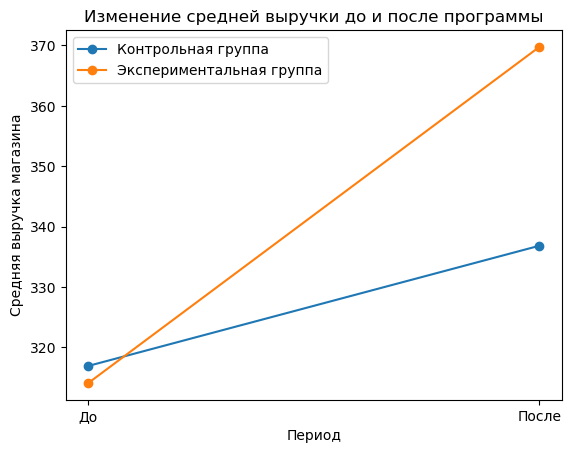

In [8]:
mean_revenue = df.groupby(['Новый_Маркетинг', 'После_Обновления'])['Выручка_Магазина'].mean()
print(mean_revenue)

control = df[df['Новый_Маркетинг'] == 0]
experiment = df[df['Новый_Маркетинг'] == 1]

control_mean = control.groupby('После_Обновления')['Выручка_Магазина'].mean()

experiment_mean = experiment.groupby('После_Обновления')['Выручка_Магазина'].mean()

plt.plot(['До', 'После'], control_mean, marker='o', label='Контрольная группа')
plt.plot(['До', 'После'], experiment_mean, marker='o', label='Экспериментальная группа')
plt.title('Изменение средней выручки до и после программы')
plt.xlabel('Период')
plt.ylabel('Средняя выручка магазина')
plt.legend()
plt.show()